In [23]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from helpers import prep_df
from LSTMNeuralArchitecture import JenaLSTMModel
import random
import matplotlib.pyplot as plt

In [24]:
class LagWindowDataset(Dataset):
    def __init__(self, data_x, data_y, seq_length=6, horizon=1):
        data_x = np.array(data_x, dtype=np.float32)
        data_y = np.array(data_y, dtype=np.float32)

        self.seq_length = seq_length
        self.horizon = horizon
        self.X = torch.FloatTensor(data_x)
        self.Y = torch.FloatTensor(data_y)

    def __len__(self):
        return len(self.X) - self.seq_length - self.horizon + 1

    def __getitem__(self, idx):
        x = self.X[idx : idx + self.seq_length]
        y = self.Y[idx + self.seq_length + self.horizon - 1]

        return x, y.unsqueeze(0)


In [25]:
df = prep_df("jena_climate_2009_2016.csv")
df_x = df.drop(columns=['Temp_Diff'])
df_y = df['Temp_Diff']

raw_x = df_x.values
raw_y = df_y.values

scaler = StandardScaler()
train_x, test_x, train_y, test_y = train_test_split(
    raw_x, raw_y,
    test_size=0.2,
    shuffle=False
)

train_x_scaled = scaler.fit_transform(train_x)
test_x_scaled = scaler.transform(test_x)

jena_train_dataset = LagWindowDataset(train_x_scaled, train_y)
jena_test_dataset = LagWindowDataset(test_x_scaled, test_y)

In [26]:
train_dataloader = DataLoader(
    jena_train_dataset,
    batch_size=128,
    shuffle=False,
)

test_dataloader = DataLoader(
    jena_test_dataset,
    batch_size=128,
    shuffle=False,
)

In [27]:
model = JenaLSTMModel(inp_size=len(train_x_scaled[0]), lstm_width=128)
criterion = nn.L1Loss()
optim = torch.optim.Adam(model.parameters(), lr=0.0003)

In [28]:
EPOCHS = 100
model_path = "jena_lstm_model.pth"

for epoch in range(EPOCHS):
    model.train()
    best_test_loss = float('inf')
    running_loss = 0.0

    for batch_idx, (X, Y) in enumerate(train_dataloader):

        optim.zero_grad()
        preds = model(X)

        loss = criterion(preds, Y)
        loss.backward()
        optim.step()

        running_loss += loss.item()

    with torch.no_grad():
        model.eval()
        test_loss = 0.0

        for batch_idx, (X, Y) in enumerate(test_dataloader):
            preds = model(X)
            loss = criterion(preds, Y)

            test_loss += loss.item()

        avg_test_loss = test_loss / len(test_dataloader)

    if avg_test_loss < best_test_loss:
        best_test_loss = avg_test_loss
        torch.save(model.state_dict(), model_path)

    print(f"Epoch: {epoch+1}    |   Loss_train: {running_loss/len(train_dataloader):.4f}    |   Loss_test: {avg_test_loss:.4f}")

Epoch: 1    |   Loss_train: 0.1415    |   Loss_test: 0.1549
Epoch: 2    |   Loss_train: 0.1377    |   Loss_test: 0.1524
Epoch: 3    |   Loss_train: 0.1332    |   Loss_test: 0.1477
Epoch: 4    |   Loss_train: 0.1295    |   Loss_test: 0.1427
Epoch: 5    |   Loss_train: 0.1278    |   Loss_test: 0.1389
Epoch: 6    |   Loss_train: 0.1261    |   Loss_test: 0.1344
Epoch: 7    |   Loss_train: 0.1242    |   Loss_test: 0.1323
Epoch: 8    |   Loss_train: 0.1229    |   Loss_test: 0.1308
Epoch: 9    |   Loss_train: 0.1221    |   Loss_test: 0.1302
Epoch: 10    |   Loss_train: 0.1214    |   Loss_test: 0.1295
Epoch: 11    |   Loss_train: 0.1210    |   Loss_test: 0.1300
Epoch: 12    |   Loss_train: 0.1206    |   Loss_test: 0.1295
Epoch: 13    |   Loss_train: 0.1202    |   Loss_test: 0.1293
Epoch: 14    |   Loss_train: 0.1200    |   Loss_test: 0.1294
Epoch: 15    |   Loss_train: 0.1198    |   Loss_test: 0.1285
Epoch: 16    |   Loss_train: 0.1194    |   Loss_test: 0.1284
Epoch: 17    |   Loss_train: 0.11

KeyboardInterrupt: 

In [29]:
seq_length = jena_test_dataset.seq_length
horizon = jena_test_dataset.horizon
max_idx = len(jena_test_dataset) - 1

random_idx = random.randint(30, max_idx)

x_sample, y_sample = jena_test_dataset[random_idx]

print(f"X shape: {x_sample.shape}")
print(f"real delta y to predict: {y_sample.item()}")

X shape: torch.Size([6, 7])
real delta y to predict: 0.0


In [30]:
model.eval()
all_preds = []
all_actuals = []

with torch.no_grad():
    for X_batch, Y_batch in test_dataloader:
        preds = model(X_batch)

        all_preds.append(preds.cpu().numpy())
        all_actuals.append(Y_batch.cpu().numpy())

all_preds = np.concatenate(all_preds, axis=0)
all_actuals = np.concatenate(all_actuals, axis=0)

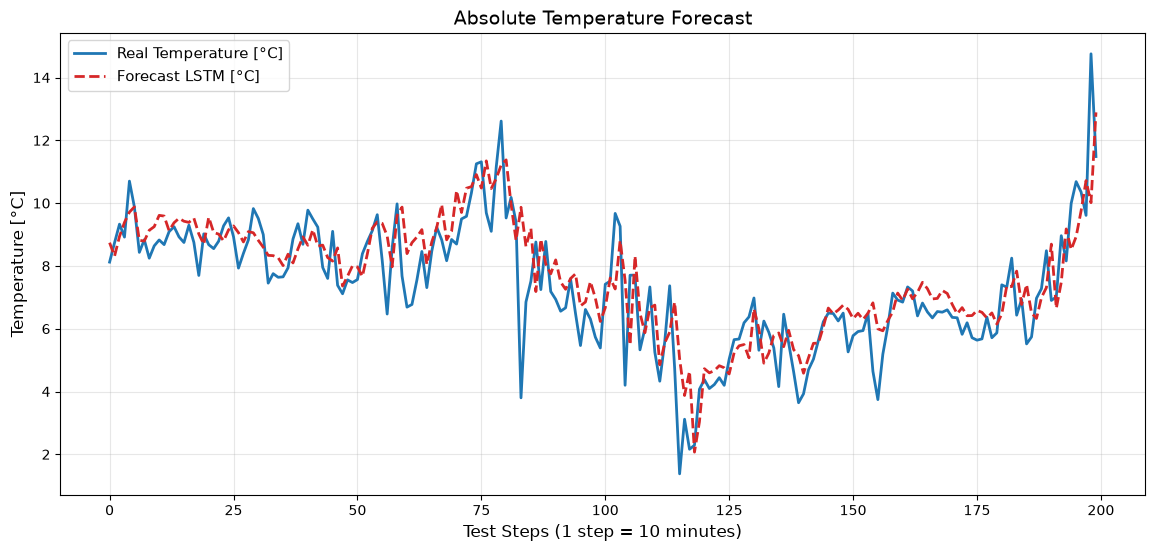

In [47]:
current_temps_scaled = []
with torch.no_grad():
    for X_batch, Y_batch in test_dataloader:
        curr_temp = X_batch[:, -1, 0].numpy()
        current_temps_scaled.append(curr_temp)

current_temps_scaled = np.concatenate(current_temps_scaled, axis=0)

temp_mean = scaler.mean_[1]
temp_scale = scaler.scale_[1]

current_temps_celsius = (current_temps_scaled * temp_scale) + temp_mean

preds_delta_celsius = all_preds.squeeze() * temp_scale
actuals_delta_celsius = all_actuals.squeeze() * temp_scale

preds_absolute = current_temps_celsius + preds_delta_celsius
actuals_absolute = current_temps_celsius + actuals_delta_celsius

plt.figure(figsize=(14, 6))

start_idx = 0
slice_len = 200

plt.plot(actuals_absolute[start_idx : start_idx + slice_len], label='Real Temperature [°C]', color='tab:blue', linewidth=2)
plt.plot(preds_absolute[start_idx : start_idx + slice_len], label='Forecast LSTM [°C]', color='tab:red', linestyle='--', linewidth=2)

plt.title('Absolute Temperature Forecast', fontsize=14)
plt.xlabel('Test Steps (1 step = 10 minutes)', fontsize=12)
plt.ylabel('Temperature [°C]', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.show()